## 1. Khởi tạo Spark

In [1]:
import os, sys, time

os.environ["SPARK_LOCAL_IP"] = "127.0.0.1"
os.environ["PYSPARK_PYTHON"] = sys.executable
# Spark trên Windows cần hadoop.dll trong PATH để ghi file
os.environ["PATH"] = os.path.join(os.environ.get("HADOOP_HOME", r"C:\hadoop"), "bin") + os.pathsep + os.environ["PATH"]

import pandas as pd
from pyspark.sql import SparkSession, functions as F
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.regression import LinearRegression, RandomForestRegressor, GBTRegressor

spark = (SparkSession.builder
         .master("local[*]")
         .appName("RussiaRealEstateModeling")
         .config("spark.driver.memory", "8g")
         .config("spark.sql.shuffle.partitions", "16")
         .getOrCreate())
spark.version

'3.5.3'

## 2. Đọc dữ liệu

Tập train là toàn bộ `train_model.parquet`; tập đánh giá là 2 tháng đầu của tập test (`months_since_start` 39–40, tức 02/05–30/06/2021).

In [2]:
train = spark.read.parquet("../data/train_model.parquet")
test = spark.read.parquet("../data/test_model.parquet").filter(F.col("months_since_start") <= 40)
print(f"Train: {train.count():,} bản ghi | Test (2 tháng đầu): {test.count():,} bản ghi")

Train: 5,459,594 bản ghi | Test (2 tháng đầu): 1,677,481 bản ghi


## 3. Chuẩn bị đặc trưng

Gộp các đặc trưng thành một vector; mô hình học trên log(`price`) vì giá lệch phải mạnh và tăng theo tỷ lệ, dự đoán được đổi ngược về rúp khi tính metric (đặt `TARGET_LOG = False` để học trực tiếp trên giá).

In [3]:
TARGET_LOG = True
FEATURES = [c for c in train.columns if c != "price"]
assembler = VectorAssembler(inputCols=FEATURES, outputCol="features")
label = F.log("price") if TARGET_LOG else F.col("price").cast("double")

train_vec = assembler.transform(train).withColumn("label", label).select("features", "label").cache()
test_vec = assembler.transform(test).withColumn("label", label).select("price", "features", "label").cache()
print(f"{len(FEATURES)} đặc trưng:", FEATURES)
print(f"Đã cache: train {train_vec.count():,} | test {test_vec.count():,}")

16 đặc trưng: ['geo_lat', 'geo_lon', 'distance_to_capital', 'area', 'rooms', 'is_studio', 'level', 'level_ratio', 'pre_owned_house', 'months_since_start', 'is_moscow_or_spb', 'bt_block', 'bt_brick', 'bt_monolithic', 'bt_others', 'bt_wooden']
Đã cache: train 5,459,594 | test 1,677,481


## 4. Huấn luyện và đánh giá

Hàm tính R², MAE, RMSE, MAPE trên giá gốc (rúp) bằng phép tổng hợp của Spark.

In [4]:
def evaluate(pred):
    p = pred.withColumn("pred_price", F.exp("prediction") if TARGET_LOG else F.col("prediction"))
    err = F.col("price") - F.col("pred_price")
    r = p.agg(F.avg(F.abs(err)).alias("MAE"),
              F.sqrt(F.avg(err ** 2)).alias("RMSE"),
              (100 * F.avg(F.abs(err) / F.col("price"))).alias("MAPE"),
              F.sum(err ** 2).alias("ss_res"),
              F.avg("price").alias("mean_price")).first()
    ss_tot = p.agg(F.sum((F.col("price") - F.lit(r["mean_price"])) ** 2)).first()[0]
    return {"R2": 1 - r["ss_res"] / ss_tot, "MAE": r["MAE"], "RMSE": r["RMSE"], "MAPE (%)": r["MAPE"]}

Huấn luyện Linear Regression, Random Forest và GBT trên toàn bộ tập train (tham số mặc định hợp lý, chưa tinh chỉnh), rồi đánh giá trên 2 tháng đầu của tập test.

In [5]:
models = {
    "Linear Regression": LinearRegression(featuresCol="features", labelCol="label"),
    "Random Forest": RandomForestRegressor(featuresCol="features", labelCol="label", numTrees=30, maxDepth=10, seed=42),
    "GBT": GBTRegressor(featuresCol="features", labelCol="label", maxIter=30, maxDepth=6, seed=42),
}
results, fitted = {}, {}
for name, estimator in models.items():
    t0 = time.time()
    fitted[name] = estimator.fit(train_vec)
    fit_time = time.time() - t0
    results[name] = {**evaluate(fitted[name].transform(test_vec)), "Thời gian huấn luyện (s)": fit_time}
    print(f"{name}: xong sau {fit_time:.0f}s")

metrics = pd.DataFrame(results).T
metrics.style.format({"R2": "{:.4f}", "MAE": "{:,.0f}", "RMSE": "{:,.0f}", "MAPE (%)": "{:.2f}",
                      "Thời gian huấn luyện (s)": "{:.0f}"})

Linear Regression: xong sau 10s
Random Forest: xong sau 414s
GBT: xong sau 354s


,R2,MAE,RMSE,MAPE (%),Thời gian huấn luyện (s)
Linear Regression,0.3958,"2,225,274","6,693,931",39.60,10
Random Forest,0.6520,"1,637,606","5,079,920",26.84,414
GBT,0.7383,"1,406,028","4,405,713",24.21,354


## 5. Độ quan trọng đặc trưng

Độ quan trọng (`featureImportances`) của Random Forest và GBT đã huấn luyện ở trên, xếp theo GBT.

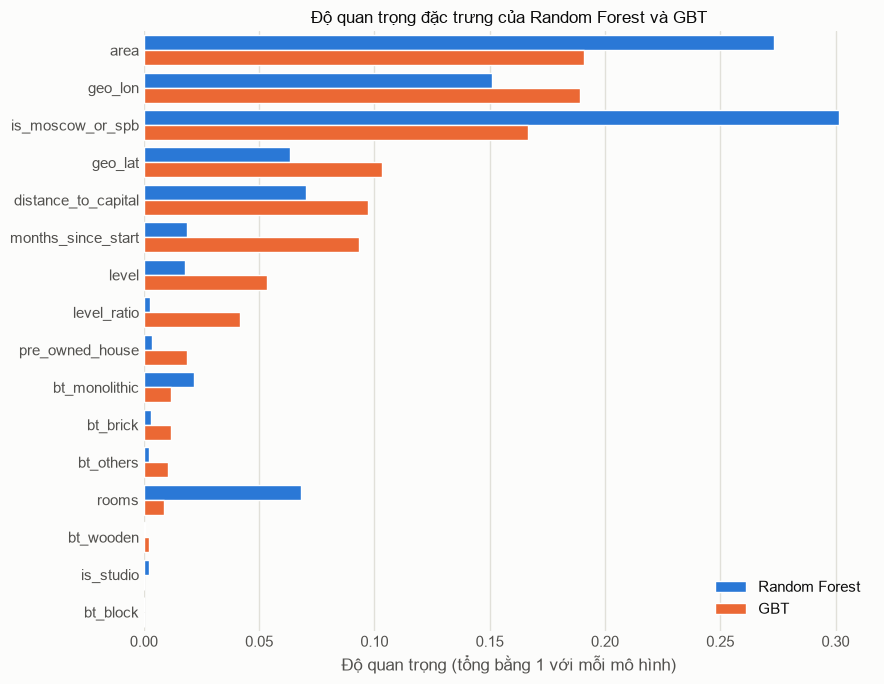

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="white", rc={
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "grid.color": "#e1e0d9",
    "text.color": "#0b0b0b", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
})
importance = (pd.DataFrame({name: fitted[name].featureImportances.toArray() for name in ["Random Forest", "GBT"]},
                           index=FEATURES)
                .sort_values("GBT", ascending=False))
imp_long = importance.rename_axis("feature").reset_index().melt(id_vars="feature", var_name="model", value_name="importance")

fig, ax = plt.subplots(figsize=(9, 7))
sns.barplot(data=imp_long, x="importance", y="feature", hue="model", hue_order=["Random Forest", "GBT"],
            palette={"Random Forest": "#2a78d6", "GBT": "#eb6834"}, saturation=1, ax=ax)
ax.set(xlabel="Độ quan trọng (tổng bằng 1 với mỗi mô hình)", ylabel=None, title="Độ quan trọng đặc trưng của Random Forest và GBT")
ax.legend(title=None, frameon=False, loc="lower right")
ax.grid(axis="x", linewidth=1)
ax.set_axisbelow(True)
ax.tick_params(length=0)
sns.despine(left=True, bottom=True)
plt.tight_layout()
plt.show()